##Step 1 — Verify the dataset

In [ ]:

from google.colab import drive
drive.mount('/content/drive')

import os

BASE_DIR = "/content/drive/MyDrive/PCOS_Project"
CLEAN_DIR = os.path.join(BASE_DIR, "CLEAN_DATASET")
SPLIT_DIR = os.path.join(BASE_DIR, "SPLIT_DATASET")

def count_images(folder):
    if not os.path.isdir(folder):
        return "FOLDER NOT FOUND"

    extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
    return sum(
        1 for name in os.listdir(folder)
        if name.lower().endswith(extensions)
    )

for name, path in [
    ("Clean dataset", CLEAN_DIR),
    ("Training dataset", os.path.join(SPLIT_DIR, "train")),
    ("Testing dataset", os.path.join(SPLIT_DIR, "test"))
]:
    print(f"\n{name}:")
    for class_name in ["infected", "noninfected"]:
        print(
            f"  {class_name}:",
            count_images(os.path.join(path, class_name))
        )


Mounted at /content/drive

Clean dataset:
  infected: 3150
  noninfected: 778

Training dataset:
  infected: 2520
  noninfected: 622

Testing dataset:
  infected: 630
  noninfected: 156


##Step 2 — Prepare the data loaders

In [ ]:

import os
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# Dataset paths
BASE_DIR = "/content/drive/MyDrive/PCOS_Project"
SPLIT_DIR = os.path.join(BASE_DIR, "SPLIT_DATASET")
TRAIN_DIR = os.path.join(SPLIT_DIR, "train")
TEST_DIR = os.path.join(SPLIT_DIR, "test")

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# ImageNet normalization (same as ResNet50)
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

# Training transformations
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(5),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

# Testing transformations: no random augmentation
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

# Load datasets
train_dataset = datasets.ImageFolder(
    TRAIN_DIR, transform=train_transform
)
test_dataset = datasets.ImageFolder(
    TEST_DIR, transform=test_transform
)

# Data loaders
train_loader = DataLoader(
    train_dataset, batch_size=32,
    shuffle=True, num_workers=2
)
test_loader = DataLoader(
    test_dataset, batch_size=32,
    shuffle=False, num_workers=2
)

# Verify
print("Class mapping:", train_dataset.class_to_idx)
print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

images, labels = next(iter(train_loader))
print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)


Device: cuda
Class mapping: {'infected': 0, 'noninfected': 1}
Training images: 3142
Testing images: 786
Training batches: 99
Testing batches: 25
Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])


##Step 3 — Load pretrained EfficientNetB0

In [ ]:

import torch
import torch.nn as nn
from torchvision import models

# Confirm device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Load ImageNet-pretrained EfficientNetB0
weights = models.EfficientNet_B0_Weights.DEFAULT
model = models.efficientnet_b0(weights=weights)

# Replace the final classification layer
num_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(num_features, 2)

# Move model to GPU
model = model.to(device)

print("Model: EfficientNetB0")
print("Pretrained weights: ImageNet")
print("Input features to final layer:", num_features)
print("Output classes:", model.classifier[1].out_features)
print("Model loaded successfully.")


Device: cuda
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 114MB/s] 


Model: EfficientNetB0
Pretrained weights: ImageNet
Input features to final layer: 1280
Output classes: 2
Model loaded successfully.


##Step 4 — Configure the loss function and optimizer

In [ ]:

import torch.nn as nn
import torch.optim as optim

# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.0001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)
print("Training configuration ready.")


Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.0001
Trainable parameters: 4010110
Training configuration ready.


##Step 5 — Train baseline EfficientNetB0

In [ ]:

import time
import torch

NUM_EPOCHS = 5
train_history = []

for epoch in range(NUM_EPOCHS):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0
    start_time = time.time()

    for batch_idx, (images, labels) in enumerate(train_loader):
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        if (batch_idx + 1) % 10 == 0 or batch_idx + 1 == len(train_loader):
            print(
                f"Epoch {epoch + 1}/{NUM_EPOCHS} | "
                f"Batch {batch_idx + 1}/{len(train_loader)} | "
                f"Loss so far: {running_loss / total:.4f}",
                flush=True
            )

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total
    elapsed = (time.time() - start_time) / 60

    train_history.append({
        "epoch": epoch + 1,
        "loss": epoch_loss,
        "accuracy": epoch_accuracy
    })

    print(
        f"COMPLETED Epoch [{epoch + 1}/{NUM_EPOCHS}] | "
        f"Loss: {epoch_loss:.4f} | "
        f"Accuracy: {epoch_accuracy:.2f}% | "
        f"Time: {elapsed:.2f} min\n",
        flush=True
    )

print("EfficientNetB0 baseline training completed.")


Epoch 1/5 | Batch 10/99 | Loss so far: 0.6654
Epoch 1/5 | Batch 20/99 | Loss so far: 0.5496
Epoch 1/5 | Batch 30/99 | Loss so far: 0.4646
Epoch 1/5 | Batch 40/99 | Loss so far: 0.3958
Epoch 1/5 | Batch 50/99 | Loss so far: 0.3448
Epoch 1/5 | Batch 60/99 | Loss so far: 0.3075
Epoch 1/5 | Batch 70/99 | Loss so far: 0.2759
Epoch 1/5 | Batch 80/99 | Loss so far: 0.2492
Epoch 1/5 | Batch 90/99 | Loss so far: 0.2281
Epoch 1/5 | Batch 99/99 | Loss so far: 0.2118
COMPLETED Epoch [1/5] | Loss: 0.2118 | Accuracy: 92.78% | Time: 2.46 min

Epoch 2/5 | Batch 10/99 | Loss so far: 0.0512
Epoch 2/5 | Batch 20/99 | Loss so far: 0.0457
Epoch 2/5 | Batch 30/99 | Loss so far: 0.0427
Epoch 2/5 | Batch 40/99 | Loss so far: 0.0395
Epoch 2/5 | Batch 50/99 | Loss so far: 0.0442
Epoch 2/5 | Batch 60/99 | Loss so far: 0.0432
Epoch 2/5 | Batch 70/99 | Loss so far: 0.0410
Epoch 2/5 | Batch 80/99 | Loss so far: 0.0420
Epoch 2/5 | Batch 90/99 | Loss so far: 0.0413
Epoch 2/5 | Batch 99/99 | Loss so far: 0.0415
COMPLE

##Step 6 — Save the trained baseline model

In [ ]:

import os
import torch

SAVE_DIR = "/content/drive/MyDrive/PCOS_Project/model_checkpoints"
os.makedirs(SAVE_DIR, exist_ok=True)

checkpoint_path = os.path.join(
    SAVE_DIR, "efficientnetb0_baseline.pth"
)

torch.save({
    "model_state_dict": model.state_dict(),
    "class_to_idx": train_dataset.class_to_idx,
    "epochs_trained": 5,
    "image_size": 224
}, checkpoint_path)

print("EfficientNetB0 baseline saved successfully!")
print("Saved to:", checkpoint_path)
print(
    "File size (MB):",
    round(os.path.getsize(checkpoint_path) / (1024 * 1024), 2)
)


EfficientNetB0 baseline saved successfully!
Saved to: /content/drive/MyDrive/PCOS_Project/model_checkpoints/efficientnetb0_baseline.pth
File size (MB): 15.59


##Step 7: Evaluate EfficientNetB0 baseline

In [ ]:
import torch
import numpy as np
from torchvision import models
from torch import nn
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Rebuild the EfficientNetB0 architecture
model_eval = models.efficientnet_b0(weights=None)
num_features = model_eval.classifier[1].in_features
model_eval.classifier[1] = nn.Linear(num_features, 2)

# Load the saved baseline checkpoint
checkpoint_path = (
    "/content/drive/MyDrive/PCOS_Project/"
    "model_checkpoints/efficientnetb0_baseline.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model_eval.load_state_dict(checkpoint["model_state_dict"])
model_eval = model_eval.to(device)
model_eval.eval()

# Evaluate on the existing test dataset
y_true = []
y_pred = []
y_prob = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model_eval(images)

        probabilities = torch.softmax(outputs, dim=1)
        predictions = torch.argmax(outputs, dim=1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())
        y_prob.extend(probabilities[:, 1].cpu().numpy())

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred)
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

print("EfficientNetB0 Baseline — Test Results")
print("=" * 45)
print(f"Test images: {len(y_true)}")
print(f"Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["infected", "noninfected"],
    digits=4,
    zero_division=0
))

print("Confusion Matrix:")
print(cm)

print(
    "\nROC-AUC (noninfected as positive class):",
    round(roc_auc_score(y_true, y_prob), 4)
)

EfficientNetB0 Baseline — Test Results
Test images: 786
Accuracy: 98.85%

Classification Report:
              precision    recall  f1-score   support

    infected     0.9936    0.9921    0.9929       630
 noninfected     0.9682    0.9744    0.9712       156

    accuracy                         0.9885       786
   macro avg     0.9809    0.9832    0.9820       786
weighted avg     0.9886    0.9885    0.9886       786

Confusion Matrix:
[[625   5]
 [  4 152]]

ROC-AUC (noninfected as positive class): 0.9924


##Step 8: Plot the EfficientNetB0 confusion matrix and ROC curve

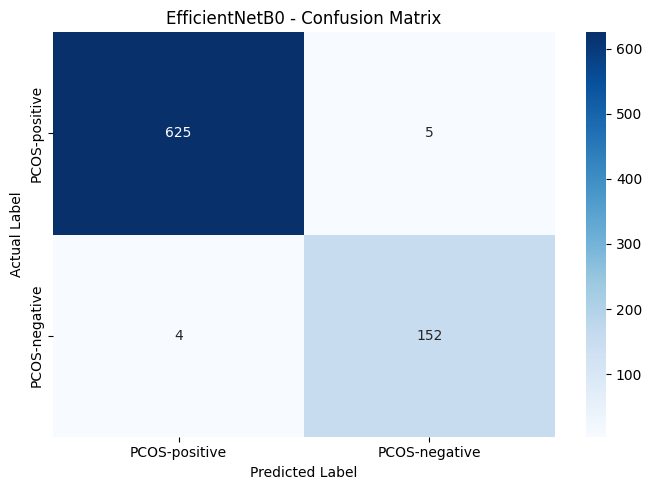

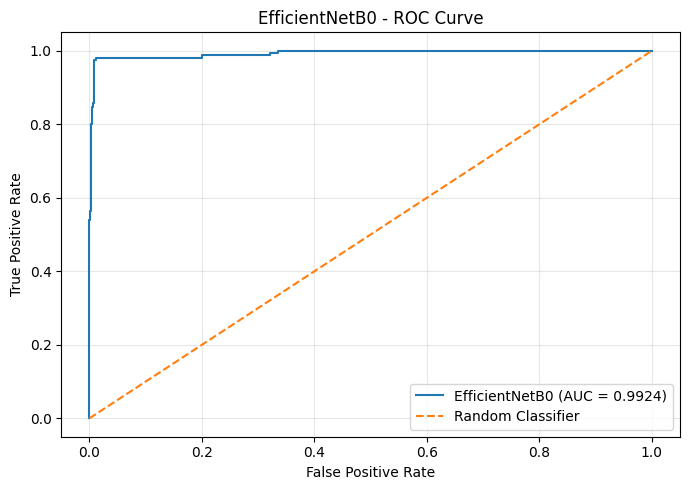

ROC-AUC: 0.9924
Both plots saved in your PCOS_Project folder.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import torch
from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    roc_auc_score
)
from torchvision import models
from torch import nn

# Load the saved baseline model
plot_model = models.efficientnet_b0(weights=None)
plot_model.classifier[1] = nn.Linear(
    plot_model.classifier[1].in_features, 2
)

checkpoint = torch.load(
    "/content/drive/MyDrive/PCOS_Project/"
    "model_checkpoints/efficientnetb0_baseline.pth",
    map_location=device,
    weights_only=True
)

plot_model.load_state_dict(checkpoint["model_state_dict"])
plot_model = plot_model.to(device)
plot_model.eval()

# Generate predictions on the same test split
y_true_plot = []
y_pred_plot = []
y_prob_plot = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        probabilities = torch.softmax(plot_model(images), dim=1)

        y_true_plot.extend(labels.numpy())
        y_pred_plot.extend(
            probabilities.argmax(dim=1).cpu().numpy()
        )
        y_prob_plot.extend(
            probabilities[:, 1].cpu().numpy()
        )

y_true_plot = np.array(y_true_plot)
y_pred_plot = np.array(y_pred_plot)
y_prob_plot = np.array(y_prob_plot)

# 1. Confusion Matrix
cm = confusion_matrix(
    y_true_plot, y_pred_plot, labels=[0, 1]
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["PCOS-positive", "PCOS-negative"],
    yticklabels=["PCOS-positive", "PCOS-negative"]
)
plt.title("EfficientNetB0 - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.savefig(
    "/content/drive/MyDrive/PCOS_Project/"
    "efficientnetb0_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 2. ROC-AUC Curve
# Class 1 is noninfected / PCOS-negative in this dataset.
fpr, tpr, thresholds = roc_curve(
    y_true_plot, y_prob_plot, pos_label=1
)
auc_score = roc_auc_score(y_true_plot, y_prob_plot)

plt.figure(figsize=(7, 5))
plt.plot(
    fpr, tpr,
    label=f"EfficientNetB0 (AUC = {auc_score:.4f})"
)
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("EfficientNetB0 - ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    "/content/drive/MyDrive/PCOS_Project/"
    "efficientnetb0_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("ROC-AUC:", round(auc_score, 4))
print("Both plots saved in your PCOS_Project folder.")

##Step 9: Load the baseline and prepare class weights

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models

# Load a separate copy of the baseline model
weighted_model = models.efficientnet_b0(weights=None)
num_features = weighted_model.classifier[1].in_features
weighted_model.classifier[1] = nn.Linear(num_features, 2)

checkpoint_path = (
    "/content/drive/MyDrive/PCOS_Project/"
    "model_checkpoints/efficientnetb0_baseline.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

weighted_model.load_state_dict(checkpoint["model_state_dict"])
weighted_model = weighted_model.to(device)

# Calculate class weights using the training dataset
class_counts = torch.bincount(
    torch.tensor(train_dataset.targets, dtype=torch.long)
).float()

class_weights = (
    class_counts.sum() / (len(class_counts) * class_counts)
).to(device)

# Weighted loss and optimizer
criterion_weighted = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer_weighted = optim.Adam(
    weighted_model.parameters(),
    lr=0.0001
)

print("Model loaded successfully.")
print("Training class counts:", class_counts.tolist())
print("Class weights:", class_weights.cpu().tolist())
print("Loss function:", criterion_weighted)
print("Optimizer: Adam")
print("Learning rate: 0.0001")

Model loaded successfully.
Training class counts: [2520.0, 622.0]
Class weights: [0.6234126687049866, 2.525723457336426]
Loss function: CrossEntropyLoss()
Optimizer: Adam
Learning rate: 0.0001


##Step 10: Train the class-weighted model

In [ ]:
import time
import torch

num_epochs = 5

for epoch in range(num_epochs):
    weighted_model.train()

    running_loss = 0.0
    correct = 0
    total = 0
    start_time = time.time()

    for batch_idx, (images, labels) in enumerate(train_loader):
        images = images.to(device)
        labels = labels.to(device)

        optimizer_weighted.zero_grad()

        outputs = weighted_model(images)
        loss = criterion_weighted(outputs, labels)

        loss.backward()
        optimizer_weighted.step()

        running_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        if (batch_idx + 1) % 10 == 0 or (batch_idx + 1) == len(train_loader):
            print(
                f"Epoch [{epoch + 1}/{num_epochs}] "
                f"Batch [{batch_idx + 1}/{len(train_loader)}]"
            )

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total
    elapsed = (time.time() - start_time) / 60

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Loss: {epoch_loss:.4f} | "
        f"Accuracy: {epoch_accuracy:.2f}% | "
        f"Time: {elapsed:.2f} min"
    )

print("\nEfficientNetB0 class-weighted training completed!")

Epoch [1/5] Batch [10/99]
Epoch [1/5] Batch [20/99]
Epoch [1/5] Batch [30/99]
Epoch [1/5] Batch [40/99]
Epoch [1/5] Batch [50/99]
Epoch [1/5] Batch [60/99]
Epoch [1/5] Batch [70/99]
Epoch [1/5] Batch [80/99]
Epoch [1/5] Batch [90/99]
Epoch [1/5] Batch [99/99]
Epoch [1/5] Loss: 0.0310 | Accuracy: 99.11% | Time: 0.41 min
Epoch [2/5] Batch [10/99]
Epoch [2/5] Batch [20/99]
Epoch [2/5] Batch [30/99]
Epoch [2/5] Batch [40/99]
Epoch [2/5] Batch [50/99]
Epoch [2/5] Batch [60/99]
Epoch [2/5] Batch [70/99]
Epoch [2/5] Batch [80/99]
Epoch [2/5] Batch [90/99]
Epoch [2/5] Batch [99/99]
Epoch [2/5] Loss: 0.0226 | Accuracy: 99.30% | Time: 0.38 min
Epoch [3/5] Batch [10/99]
Epoch [3/5] Batch [20/99]
Epoch [3/5] Batch [30/99]
Epoch [3/5] Batch [40/99]
Epoch [3/5] Batch [50/99]
Epoch [3/5] Batch [60/99]
Epoch [3/5] Batch [70/99]
Epoch [3/5] Batch [80/99]
Epoch [3/5] Batch [90/99]
Epoch [3/5] Batch [99/99]
Epoch [3/5] Loss: 0.0196 | Accuracy: 99.40% | Time: 0.38 min
Epoch [4/5] Batch [10/99]
Epoch [4/5]

##Step 11: Save the class-weighted model

In [ ]:
import os
import torch

SAVE_DIR = "/content/drive/MyDrive/PCOS_Project/model_checkpoints"
os.makedirs(SAVE_DIR, exist_ok=True)

checkpoint_path = os.path.join(
    SAVE_DIR, "efficientnetb0_class_weighted.pth"
)

torch.save({
    "model_state_dict": weighted_model.state_dict(),
    "class_to_idx": train_dataset.class_to_idx,
    "epochs_trained": 5,
    "image_size": 224,
    "class_weights": class_weights.cpu().tolist()
}, checkpoint_path)

print("EfficientNetB0 class-weighted model saved successfully!")
print("Saved to:", checkpoint_path)
print(
    "File size (MB):",
    round(os.path.getsize(checkpoint_path) / (1024 * 1024), 2)
)

EfficientNetB0 class-weighted model saved successfully!
Saved to: /content/drive/MyDrive/PCOS_Project/model_checkpoints/efficientnetb0_class_weighted.pth
File size (MB): 15.59


##Step 12: Evaluate the class-weighted model

In [ ]:
import torch
import torch.nn as nn
from torchvision import models
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Rebuild the model architecture
weighted_eval = models.efficientnet_b0(weights=None)
weighted_eval.classifier[1] = nn.Linear(
    weighted_eval.classifier[1].in_features, 2
)

# Load saved class-weighted checkpoint
checkpoint_path = (
    "/content/drive/MyDrive/PCOS_Project/"
    "model_checkpoints/efficientnetb0_class_weighted.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

weighted_eval.load_state_dict(checkpoint["model_state_dict"])
weighted_eval = weighted_eval.to(device)
weighted_eval.eval()

# Predict on test set
y_true_weighted = []
y_pred_weighted = []
y_prob_weighted = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = weighted_eval(images)
        probabilities = torch.softmax(outputs, dim=1)

        y_true_weighted.extend(labels.numpy())
        y_pred_weighted.extend(
            probabilities.argmax(dim=1).cpu().numpy()
        )
        y_prob_weighted.extend(
            probabilities[:, 1].cpu().numpy()
        )

# Calculate evaluation metrics
accuracy = accuracy_score(y_true_weighted, y_pred_weighted)
cm = confusion_matrix(
    y_true_weighted, y_pred_weighted, labels=[0, 1]
)
auc = roc_auc_score(y_true_weighted, y_prob_weighted)

print("EfficientNetB0 Class-Weighted Test Results")
print("=" * 48)
print(f"Test images: {len(y_true_weighted)}")
print(f"Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_true_weighted,
    y_pred_weighted,
    labels=[0, 1],
    target_names=["infected", "noninfected"],
    digits=4,
    zero_division=0
))

print("Confusion Matrix:")
print(cm)
print(f"\nROC-AUC (noninfected positive class): {auc:.4f}")

EfficientNetB0 Class-Weighted Test Results
Test images: 786
Accuracy: 98.73%

Classification Report:
              precision    recall  f1-score   support

    infected     0.9936    0.9905    0.9921       630
 noninfected     0.9620    0.9744    0.9682       156

    accuracy                         0.9873       786
   macro avg     0.9778    0.9824    0.9801       786
weighted avg     0.9874    0.9873    0.9873       786

Confusion Matrix:
[[624   6]
 [  4 152]]

ROC-AUC (noninfected positive class): 0.9975


##Step 14: Save the class-weighted evaluation plots

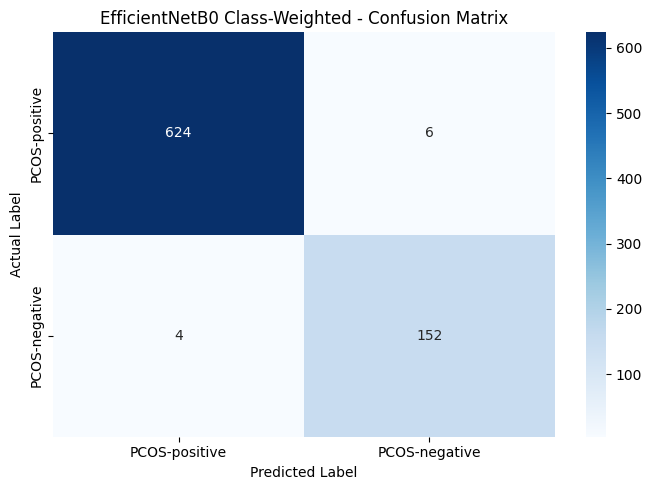

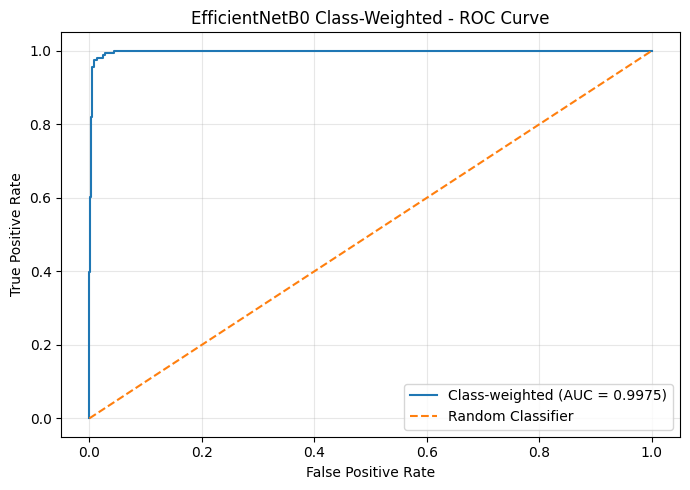

Class-weighted plots saved successfully.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score
import os

PLOT_DIR = "/content/drive/MyDrive/PCOS_Project"
os.makedirs(PLOT_DIR, exist_ok=True)

# 1. Class-weighted confusion matrix
cm_weighted = confusion_matrix(
    y_true_weighted,
    y_pred_weighted,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_weighted,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["PCOS-positive", "PCOS-negative"],
    yticklabels=["PCOS-positive", "PCOS-negative"]
)
plt.title("EfficientNetB0 Class-Weighted - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.savefig(
    os.path.join(PLOT_DIR, "efficientnetb0_weighted_confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# 2. Class-weighted ROC curve
fpr, tpr, _ = roc_curve(
    y_true_weighted,
    y_prob_weighted,
    pos_label=1
)
auc_score = roc_auc_score(y_true_weighted, y_prob_weighted)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Class-weighted (AUC = {auc_score:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("EfficientNetB0 Class-Weighted - ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(PLOT_DIR, "efficientnetb0_weighted_roc_curve.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Class-weighted plots saved successfully.")

 Compared with the baseline model, class weighting improved ROC-AUC but did not improve overall accuracy or minority-class recall. Therefore, class weighting did not provide a clear overall performance improvement in this experiment.